In [83]:
import re
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

RANDOM_STATE = 42
CSV_PATH = "/Users/swajith/Downloads/WELFake_Dataset.csv"

# One place for the label mapping (verify in Cell 3)
LABEL_NAMES = {0: "Real News", 1: "Fake News"}

In [84]:
data = pd.read_csv(CSV_PATH)


In [85]:
print(data.shape)


(72134, 4)


In [86]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  72134 non-null  int64
 1   title       71576 non-null  str  
 2   text        72095 non-null  str  
 3   label       72134 non-null  int64
dtypes: int64(2), str(2)
memory usage: 235.0 MB


In [87]:
print(data.isnull().sum())



Unnamed: 0      0
title         558
text           39
label           0
dtype: int64


In [100]:
print(data['label'].value_counts())
print("--"*40)
data['label'].value_counts(normalize = True)*100

label
1    36509
0    35028
Name: count, dtype: int64
--------------------------------------------------------------------------------


label
1   51.035
0   48.965
Name: proportion, dtype: float64

In [88]:
# FIX: assign the result, and drop the column only once
data = data.drop(columns=["Unnamed: 0"], errors="ignore")



In [89]:
# FIX: drop missing values BEFORE sampling
data = data.dropna(subset=["title", "text", "label"])

print(data["label"].value_counts())
print(data["label"].value_counts(normalize=True) * 100)

label
1    36509
0    35028
Name: count, dtype: int64
label
1   51.035
0   48.965
Name: proportion, dtype: float64


In [68]:
for lbl in [0, 1]:
    print(f"\n===== LABEL {lbl} ({LABEL_NAMES[lbl]}) =====")
    for _, r in data[data["label"] == lbl].sample(8, random_state=1).iterrows():
        print("-", r["title"][:110])


===== LABEL 0 (Real News) =====
- Candles May Have Caused Fire That Gutted Serbian Church, Officials Say - The New York Times
- Single Mother Seeks to Give Daughter the Peace That Eluded Her - The New York Times
- Cliff Sims: House Healthcare Bill ’Still a Work in Progress’
- Only a Rumbling Volcano Could Make North Korea and the West Play Nice - The New York Times
- New Ontario Law Enables Gov’t to Seize Children from Parents Opposing Gender Transition
- EPA confirms White House freeze on grants, contracts ends Friday
- NRA gun rights group pours money into Republican U.S. Senate campaigns
- Saudi Arabia says foils Islamic State bomb, foreign spying plots

===== LABEL 1 (Fake News) =====
- TRUMP OBLITERATES “Phony Vietnam Con-Artist” Dem Senator, After He Alleged Trump Campaign Collusion With Russi
- CLUELESS IN LIBYA: CLINTON E-MAILS SHOW MORE THAN YOU MIGHT THINK
-  Trump’s White House Team Is So Dumb They Fell For Fake Emails (IMAGE)
-  After Horrific National Anthem Sung At Trump

In [69]:
n_sample = 10000

df_fake = data[data["label"] == 1].sample(n_sample, random_state=RANDOM_STATE)
df_real = data[data["label"] == 0].sample(n_sample, random_state=RANDOM_STATE)

df = (
    pd.concat([df_fake, df_real])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(df["label"].value_counts())

label
0    10000
1    10000
Name: count, dtype: int64


In [70]:
def clean_text(s: str) -> str:
    if pd.isna(s):
        return ""
    s = str(s).lower()
    s = re.sub(r"http\S+|www\S+", " ", s)   # URLs
    s = re.sub(r"<.*?>", " ", s)            # HTML tags
    s = re.sub(r"[^a-z0-9\s]", " ", s)      # special characters
    s = re.sub(r"\s+", " ", s).strip()      # extra spaces
    return s

print(clean_text("www.google.com abcdef_"))
print(clean_text("ABCDabc 123* XYZxyz 999"))

abcdef
abcdabc 123 xyzxyz 999


In [71]:
df["content"] = (df["title"] + " " + df["text"]).apply(clean_text)

df["title_len_chars"] = df["title"].str.len()
df["text_len_chars"] = df["text"].str.len()
df["content_len_word"] = df["content"].str.split().apply(len)

num_cols = ["title_len_chars", "text_len_chars", "content_len_word"]
print(df[num_cols].describe().T)

                     count     mean      std   min      25%      50%      75%  \
title_len_chars  20000.000   76.755   24.808 8.000   62.000   73.000   88.000   
text_len_chars   20000.000 3306.744 3785.363 1.000 1413.000 2439.000 4091.000   
content_len_word 20000.000  567.659  622.361 0.000  248.000  421.000  697.250   

                        max  
title_len_chars     286.000  
text_len_chars   142961.000  
content_len_word  17648.000  


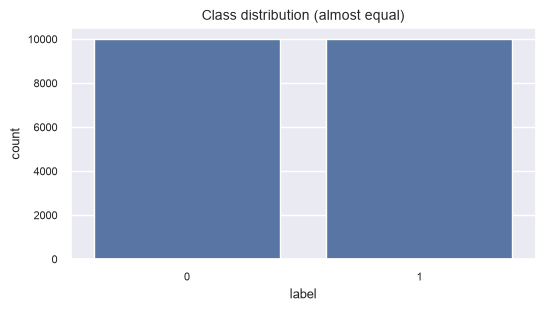

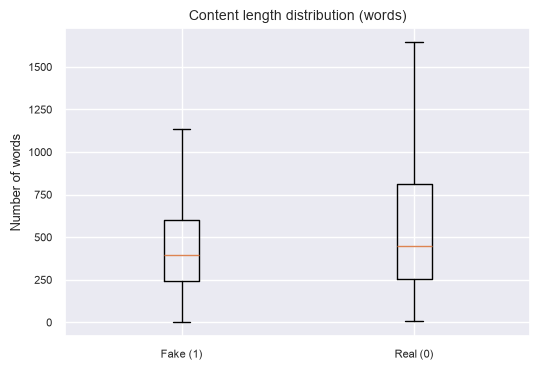

In [ ]:
plt.figure(figsize=(6, 3))
sns.countplot(x="label", data=df)
plt.title("Class distribution (almost equal)")   # FIX: was markdown in a code cell
plt.show()





In [90]:
fake_lens = df[df["label"] == 1]["content_len_word"].values
real_lens = df[df["label"] == 0]["content_len_word"].values

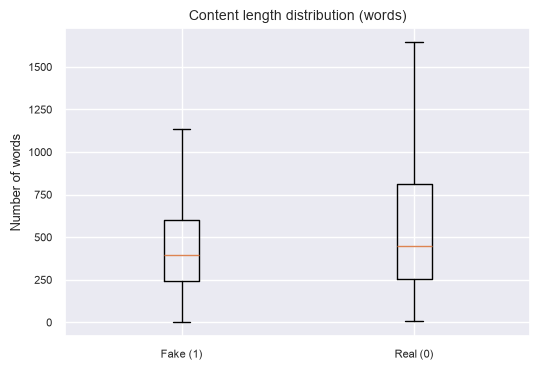

In [91]:
plt.figure(figsize=(6, 4))
plt.boxplot(
    [fake_lens, real_lens],
    tick_labels=["Fake (1)", "Real (0)"],   # use labels= on matplotlib < 3.9
    showfliers=False,
)
plt.title("Content length distribution (words)")
plt.ylabel("Number of words")
plt.show()

In [92]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 16000 | Test size: 4000


In [93]:
model_pipeline = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        stop_words="english",
        min_df=2,
    )),
    ("model", LogisticRegression(max_iter=1000)),
])

model_pipeline.fit(X_train, y_train)
print("Model classes:", model_pipeline.classes_)

Model classes: [0 1]


In [75]:
names = [LABEL_NAMES[0], LABEL_NAMES[1]]

for split, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    pred = model_pipeline.predict(Xs)
    proba = model_pipeline.predict_proba(Xs)[:, 1]

    print(f"\n===== {split} =====")
    print(f"Accuracy : {accuracy_score(ys, pred):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(ys, proba):.4f}")
    print("Confusion matrix [[TN FP], [FN TP]]:")
    print(confusion_matrix(ys, pred, labels=[0, 1]))
    print(classification_report(ys, pred, labels=[0, 1],
                                target_names=names, digits=4))
                                


===== Train =====
Accuracy : 0.9627
ROC-AUC  : 0.9932
Confusion matrix [[TN FP], [FN TP]]:
[[7662  338]
 [ 259 7741]]
              precision    recall  f1-score   support

   Real News     0.9673    0.9577    0.9625      8000
   Fake News     0.9582    0.9676    0.9629      8000

    accuracy                         0.9627     16000
   macro avg     0.9627    0.9627    0.9627     16000
weighted avg     0.9627    0.9627    0.9627     16000


===== Test =====
Accuracy : 0.9295
ROC-AUC  : 0.9825
Confusion matrix [[TN FP], [FN TP]]:
[[1843  157]
 [ 125 1875]]
              precision    recall  f1-score   support

   Real News     0.9365    0.9215    0.9289      2000
   Fake News     0.9227    0.9375    0.9301      2000

    accuracy                         0.9295      4000
   macro avg     0.9296    0.9295    0.9295      4000
weighted avg     0.9296    0.9295    0.9295      4000



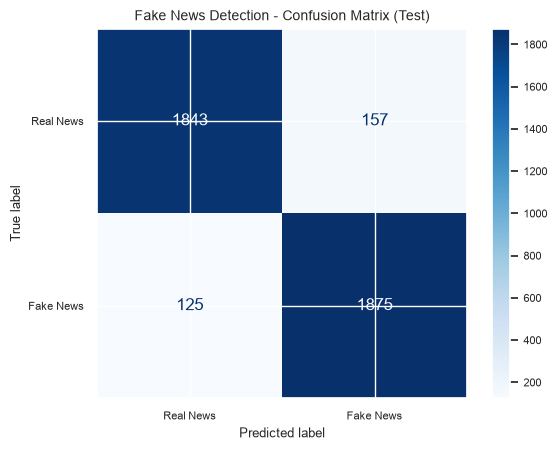

In [76]:
y_pred = model_pipeline.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=names, cmap="Blues"
)
plt.title("Fake News Detection - Confusion Matrix (Test)")
plt.show()

In [94]:
results = pd.DataFrame({"text": X_test, "actual": y_test, "predicted": y_pred})

wrong_real = results[(results["actual"] == 0) & (results["predicted"] == 1)]

print("Real articles wrongly predicted as fake:")
print(wrong_real["text"].head(5).str[:300].to_string(index=False))

Real articles wrongly predicted as fake:
loserpalooza 9 craziest scenes from anti trump protests breitbart protesters ran wild across washington d c on the eve of president donald trump s inauguration obliging the police to douse them in pepper spray i dubbed the event loserpalooza on twitter looks like loserpalooza was a smash nothing say
                                                                                                                                                                     jill s dilemma the president refuses to say he d hold to the tradition of avoiding public comment or political attacks on the successor
simple rules for healthy eating the new york times over the past few months i ve written a number of times on how nutrition recommendations are seldom supported by science i ve argued that what many people are telling you may be inaccurate in response many of you have asked me what nutrition recomme
islamic state starts 2017 with video of toddler executin

In [95]:
def predict_news(title: str, text: str) -> int:
    combined = clean_text(f"{title} {text}")
    probs = model_pipeline.predict_proba([combined])[0]
    pred = int(model_pipeline.predict([combined])[0])

    print(f"{LABEL_NAMES[0]} probability: {probs[0]:.2%}")
    print(f"{LABEL_NAMES[1]} probability: {probs[1]:.2%}")
    print(f"Prediction: {LABEL_NAMES[pred]}")
    return pred


# FIX: these variables were never defined in your version


In [96]:
tfidf = model_pipeline.named_steps["tfidf"]
clf = model_pipeline.named_steps["model"]

feature_names = tfidf.get_feature_names_out()
coefs = clf.coef_[0]          # positive = pushes toward class 1

top_class1 = coefs.argsort()[-20:][::-1]
top_class0 = coefs.argsort()[:20]

print(f"Top words for class 1 ({LABEL_NAMES[1]}):")
print([feature_names[i] for i in top_class1])

print(f"\nTop words for class 0 ({LABEL_NAMES[0]}):")
print([feature_names[i] for i in top_class0])

Top words for class 1 (Fake News):
['video', 'hillary', 'featured image', 'image', 'featured', 'watch', '2016', 'twitter com', 'just', 'getty', 'getty images', 'october', 'obama', 'com', 'read', 'america', 'november', 'fbi', 'anti', 'images']

Top words for class 0 (Real News):
['said', 'reuters', 'breitbart', 'mr', 'washington reuters', 'president donald', 'follow', 'thursday', 'ms', 'tuesday', 'monday', 'wednesday', 'twitter', 'friday', 'new york', 'york', 'percent', '2017', 'new', 'statement']


In [97]:
LABEL_NAMES = {0: "Fake News", 1: "Real News"}

In [98]:
real_style_title = "Senate passes budget bill after lengthy debate"
real_style_text = """
WASHINGTON (Reuters) - The U.S. Senate on Thursday passed a budget bill
after a lengthy debate, sending the measure to the House of Representatives,
officials said. Lawmakers said the vote followed weeks of negotiations.
"""

predict_news(real_style_title, real_style_text)

Fake News probability: 99.61%
Real News probability: 0.39%
Prediction: Fake News


0

In [99]:
example_title = "Chandrayaan-3 Successfully Lands Near the Moon's South Pole"
example_text = """
India's Chandrayaan-3 mission successfully landed near the Moon's south polar
region on August 23, 2023. The mission was developed by the Indian Space
Research Organisation (ISRO). India became the fourth country to achieve a
soft landing on the Moon.
"""

predict_news(example_title, example_text)

Fake News probability: 43.05%
Real News probability: 56.95%
Prediction: Real News


1

label
1    37106
0    35028
Name: count, dtype: int64
--------------------------------------------------------------------------------


label
1   51.4
0   48.6
Name: proportion, dtype: float64

In [39]:
#from numpy.random.mtrand import f
n_sample = 10000
#separate data
df_fake = data[data['label']==1]
df_real = data[data['label']==0]

#sample
df_fake_sample = df_fake.sample(n_sample,random_state = RANDOM_STATE)
df_real_sample = df_real.sample(n_sample,random_state = RANDOM_STATE)

#Combine and shuffle
df=(
     pd.concat([df_fake_sample,df_real_sample])
        .sample(frac = 1,random_state = RANDOM_STATE)
        .reset_index(drop = True)
)



In [40]:
print(df['label'].value_counts())
df['label'].value_counts(normalize = True)*100

label
0    10000
1    10000
Name: count, dtype: int64


label
0   50.0
1   50.0
Name: proportion, dtype: float64

In [41]:
df.drop(columns = ['Unnamed: 0'],inplace = True)

In [42]:
df.columns

Index(['title', 'text', 'label'], dtype='str')

In [43]:
df = df.dropna()

In [44]:
print(df["label"].value_counts())
print("-"*40)
df['label'].value_counts(normalize=True)*100

label
0    10000
1     9856
Name: count, dtype: int64
----------------------------------------


label
0   50.4
1   49.6
Name: proportion, dtype: float64

In [49]:
df['text']

0        If passed in its current form, the GOP’s Obamacare 2. 0 bill will impose brutal costs Americans still struggling to make it through a great recession —  particularly President Donald Trump’s base —  and risk handing Congress and the presidency back to Democrats. [1) The bill’s provisions increase healthcare costs for Trump voters in critical states. As an analysis conducted by the Washington Post shows, voters in Michigan, Pennsylvania, and Wisconsin will see their tax credits decrease under Obamacare 2. 0. “If you’re a    making $75, 000 a year, you’re going to get a 75 percent or higher increase to your tax credits —  a beneficial situation for you,” the Post explains. “If, however, you’re a    making $30, 000 a year, you’re going to see a reduction in those tax credits (unless you live in Upstate New York or Massachusetts or parts of central Texas). ”  In other words, senior citizens —  who vote regularly in   elections —  will see their healthcare costs increase under the 

In [50]:
def clean_text(s: str) -> str:
    if pd.isna(s):
        return ""

    s = str(s).lower()

    # Remove URLs
    s = re.sub(r"http\S+|www\S+", " ", s)

    # Remove HTML tags
    s = re.sub(r"<.*?>", " ", s)

    # Remove unwanted characters
    s = re.sub(r"[^a-z0-9\s]", " ", s)

    # Remove extra spaces
    s = re.sub(r"\s+", " ", s).strip()

    return s

In [51]:
a = "www.google.com"
b = "abcdef_"

c = a + " " + b

print("Before:", c)

d = clean_text(c)

print("After:", d)

Before: www.google.com abcdef_
After: abcdef


In [52]:
a = "ABCDabc 123*"
b = "XYZxyz 999"
c = a+" "+b
print(c)
d = clean_text(c)
print(d)

ABCDabc 123* XYZxyz 999
abcdabc 123 xyzxyz 999


In [53]:
df['content'] = (df['title']+" "+df['text']).apply(clean_text)

In [54]:
df.head()

title  \
0  7 Reasons Why Obamacare 2.0 Is All But Guaranteed to Impose Crushing Costs on Voters, Hurt Trump’s Base, And Hand Power Back to the Democrats - Breitbart   
1                                                 Angry Voters Trying to Flee Country Over Presidential Election Results Crash Canada’s Official Immigration   
2                                                             BLACK LEADER CALLS ON BLACK CAUCUS MEMBERS TO RESIGN: Praises Trump’s Visit To Detroit [video]   
3                                                                                         Classless Obama Refuses Photo-Op of White House Welcome with Trump   
4                                                                                                     German parties in coalition talks agree on no new debt   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [55]:
#adding additional columns for analysis
df["title_len_chars"] = df["title"].str.len()
df["text_len_chars"] = df["text"].str.len()
df["content_len_word"] = df["content"].str.split().apply(len)

In [56]:
df = df.drop(columns=["content_len_chars"], errors="ignore")


In [57]:
num_cols = ["title_len_chars","text_len_chars","content_len_word"]
print(df[num_cols].describe().T)

                    count     mean      std  min      25%      50%      75%  \
title_len_chars  1.99e+04     77.0     25.1  4.0     62.0     73.0     89.0   
text_len_chars   1.99e+04 3.28e+03 3.66e+03  1.0 1.41e+03 2.44e+03 4.08e+03   
content_len_word 1.99e+04 5.65e+02 6.26e+02  0.0 2.47e+02  4.2e+02 6.97e+02   

                      max  
title_len_chars  2.86e+02  
text_len_chars   1.15e+05  
content_len_word 2.13e+04  


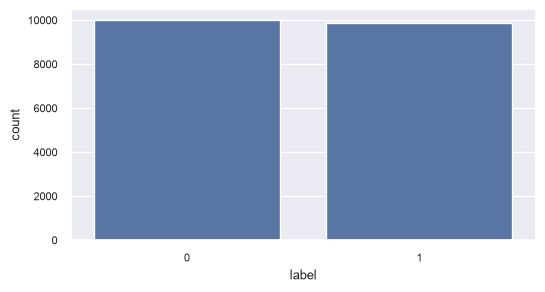

In [58]:
plt.figure(figsize=(6,3))
sns.countplot(x = "label",data = df)
plt.show()

**Note : ALmost Equal class distribution**


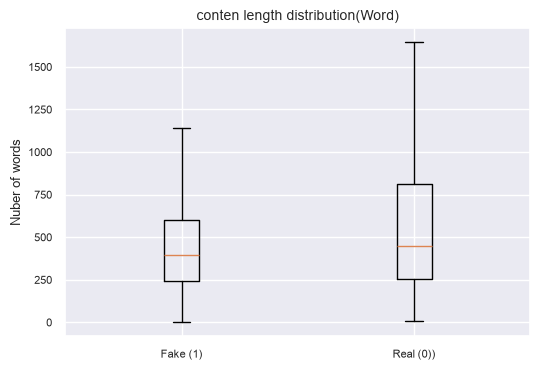

In [60]:
#text length distribution (words) - boxplot
fake_lens = df[df["label"]==1]["content_len_word"].values
real_lens = df[df["label"]==0]["content_len_word"].values
plt.figure(figsize = (6,4))
plt.boxplot(
    [fake_lens,real_lens],
    tick_labels = ["Fake (1)","Real (0))"],
    showfliers = False


)
plt.title("conten length distribution(Word)")
plt.ylabel("Nuber of words")
plt.show()



In [61]:
X = df["content"]
y = df["label"]

In [62]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    stratify = y,
    random_state=RANDOM_STATE
)

In [63]:
print("\nTrain size: ",len(X_train),"|  Test size :",len(X_test))


Train size:  15884 |  Test size : 3972


In [65]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Predict test data
predictions = model_pipeline.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Real News", "Fake News"],
    digits=4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))

NameError: name 'model_pipeline' is not defined

In [ ]:
model_pipeline = Pipeline(
    steps = [
        ("tfidf",TfidfVectorizer(
            max_features = 50000,
            ngram_range= (1,2),
            stop_words = "english",
            min_df = 2
        )),
        ("model", LogisticRegression()) 
    ]
)

In [ ]:
model_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",50000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence ite

Accuracy: 0.9350453172205438
              precision    recall  f1-score   support

   Fake News       0.94      0.93      0.94      2000
   Real News       0.93      0.94      0.93      1972

    accuracy                           0.94      3972
   macro avg       0.94      0.94      0.94      3972
weighted avg       0.94      0.94      0.94      3972



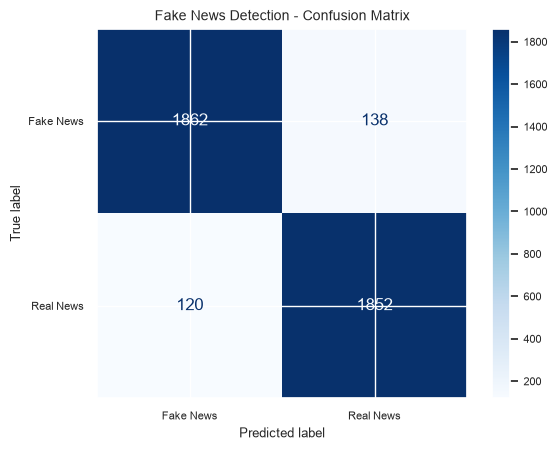

In [ ]:
# Predict on test data
y_pred = model_pipeline.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Precision, recall and F1-score
print(classification_report(
    y_test,
    y_pred,
    target_names=["Fake News", "Real News"]
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Fake News", "Real News"],
    cmap="Blues"
)

plt.title("Fake News Detection - Confusion Matrix")
plt.show()


In [ ]:

# Inspect real-news examples the model incorrectly labels as fake

import pandas as pd

predictions = model_pipeline.predict(X_test)

results = pd.DataFrame({
    "text": X_test,
    "actual": y_test,
    "predicted": predictions
})

# Assumes verified mapping: 0 = Real, 1 = Fake
wrong_real = results[
    (results["actual"] == 0) &
    (results["predicted"] == 1)
]

print("Real articles wrongly predicted as fake:")
print(wrong_real["text"].head(5).to_string(index=False))



Real articles wrongly predicted as fake:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [ ]:
# 5. Model Evaluation

y_pred_train = model_pipeline.predict(X_train)
y_proba_train = model_pipeline.predict_proba(X_train)[:, 1]

acc_train = accuracy_score(y_train, y_pred_train)
cm_train = confusion_matrix(y_train, y_pred_train)

print("\n--- Train Metrics ---")
print(f"Accuracy : {acc_train:.4f}")

print("\nConfusion Matrix [[TN FP], [FN TP]]:")
print(cm_train)

print("\nClassification Report:")
print(classification_report(y_train, y_pred_train, digits=4))


--- Train Metrics ---
Accuracy : 0.9600

Confusion Matrix [[TN FP], [FN TP]]:
[[7636  364]
 [ 272 7612]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9656    0.9545    0.9600      8000
           1     0.9544    0.9655    0.9599      7884

    accuracy                         0.9600     15884
   macro avg     0.9600    0.9600    0.9600     15884
weighted avg     0.9600    0.9600    0.9600     15884



In [ ]:

def predict_news(title, text):
    combined = clean_text(f"{title} {text}")

    probabilities = model_pipeline.predict_proba([combined])[0]
    prediction = model_pipeline.predict([combined])[0]

    print(f"Real News probability: {probabilities[0]:.2%}")
    print(f"Fake News probability: {probabilities[1]:.2%}")

    if prediction == 0:
        print("This is Real News 📰✅")
    else:
        print("This is Fake News 📰❌")

    return prediction


In [ ]:


predict_news(example_title, example_text)

Real News probability: 24.76%
Fake News probability: 75.24%
This is Fake News 📰❌


np.int64(1)

In [ ]:

import joblib

joblib.dump(model_pipeline, "final_model_pipeline.pkl")

print("Model pipeline saved successfully!")



Model pipeline saved successfully!


In [ ]:
for lbl in [0, 1]:
    print(f"\n===== LABEL {lbl} =====")
    for _, r in data[data["label"] == lbl].dropna(subset=["title"]).sample(8, random_state=1).iterrows():
        print("-", r["title"][:110])


===== LABEL 0 =====
- Candles May Have Caused Fire That Gutted Serbian Church, Officials Say - The New York Times
- Single Mother Seeks to Give Daughter the Peace That Eluded Her - The New York Times
- Cliff Sims: House Healthcare Bill ’Still a Work in Progress’
- Only a Rumbling Volcano Could Make North Korea and the West Play Nice - The New York Times
- New Ontario Law Enables Gov’t to Seize Children from Parents Opposing Gender Transition
- EPA confirms White House freeze on grants, contracts ends Friday
- NRA gun rights group pours money into Republican U.S. Senate campaigns
- Saudi Arabia says foils Islamic State bomb, foreign spying plots

===== LABEL 1 =====
- “Sex Shop Kierkegaard: punto de encuentro para amantes del placer intelectual”
- FATHER OF STUDENT Released From N. Korean Prison Slams Obama…Uses ONE WORD To Describe President Trump That Wi
- The Path To Total Dictatorship: America’s “Shadow Government” And Its Silent Coup
- John Derbyshire On Peter Thiel On Trump
- TEX

In [32]:

title = "Chandrayaan-3 Successfully Lands on the Moon"

article = """
India's Chandrayaan-3 mission successfully landed near the
Moon's south polar region on August 23, 2023. The mission
was developed by the Indian Space Research Organisation.
India became the fourth country to achieve a soft landing
on the Moon.
"""

combined = clean_text(title + " " + article)

print("Predicted class:", model_pipeline.predict([combined])[0])
print("Model classes:", model_pipeline.classes_)
print("Probabilities:", model_pipeline.predict_proba([combined])[0])


NameError: name 'model_pipeline' is not defined

In [33]:
for label in [0, 1]:
    print(f"\n{'=' * 20} LABEL {label} {'=' * 20}")

    samples = data.loc[
        data["label"] == label, ["title", "text"]
    ].dropna()

    for _, row in samples.sample(
        min(5, len(samples)), random_state=42
    ).iterrows():
        print("TITLE:", row["title"])
        print("TEXT:", str(row["text"])[:250])
        print("-" * 50)


==================== LABEL 0 ====================
TITLE: Two People Die after Eating Raw-Milk Cheese Made in New York State - The New York Times
TEXT: Two people have died following an outbreak of listeria linked to a popular artisanal raw milk cheese made in upstate New York, the authorities said this week. The deaths occurred in Vermont and Connecticut, local officials said. Four other people in 
--------------------------------------------------
TITLE: DUP blames Sinn Fein for Northern Ireland talks collapse
TEXT: BELFAST (Reuters) - A senior member of Northern Ireland s Democratic Unionist Party on Wednesday blamed rivals Sinn Fein for the collapse of talks on forming a power-sharing government and suggested the DUP would not compromise on the key issue of th
--------------------------------------------------
TITLE: Exclusive: Former top Brazil prosecutor says successor, police chief slowing graft probes
TEXT: BRASILIA (Reuters) - Three senior Brazilian law enforcement officials, 

In [34]:

# Check the model's class mapping
print("Classes:", model_pipeline.classes_)

# Test the real news article
title = "Chandrayaan-3 Successfully Lands Near the Moon's South Pole"

article = """
India's Chandrayaan-3 mission successfully landed near the
Moon's south polar region on August 23, 2023. The mission
was developed by the Indian Space Research Organisation (ISRO).
India became the fourth country to achieve a soft landing
on the Moon.
"""

combined = clean_text(title + " " + article)

print("Prediction:", model_pipeline.predict([combined])[0])
print("Probabilities:", model_pipeline.predict_proba([combined])[0])


NameError: name 'model_pipeline' is not defined

In [35]:
for label in [0, 1]:
    print(f"\n--- LABEL {label} ---")

    samples = data.loc[data["label"] == label, "title"].dropna().head(10)

    for title in samples:
        print("-", title)


--- LABEL 0 ---
- Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid
- May Brexit offer would hurt, cost EU citizens - EU parliament
- Schumer calls on Trump to appoint official to oversee Puerto Rico relief
- No Change Expected for ESPN Political Agenda Despite Huge Subscriber Decline - Breitbart
- Billionaire Odebrecht in Brazil scandal released to house arrest
- U.N. seeks humanitarian pause in Sanaa where streets "battlegrounds"
- Second judge says Clinton email setup may have been in 'bad faith'
- Supreme Court Won’t Hear Appeal From Texas on Voter ID Case - The New York Times
- Islamic State driven out of last stronghold in northern Iraq
- Senators Propose Giving States Option to Keep Affordable Care Act - The New York Times

--- LABEL 1 ---
- LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO]
- UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CH